## in the name of allah we begin new adventure in AI

In [1]:
%%capture
!pip install rdkit-pypi
!pip install torch-geometric
!pip install torch-scatter -f https://data.pyg.org/whl/torch-2.4.0+cu121.html

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import rdkit
from rdkit import Chem
from torch_geometric.loader import DataLoader
from IPython import display
from rdkit.Chem.Draw import IPythonConsole
import pandas
import rdkit.Chem.Lipinski as Lipinsky
from rdkit.Chem.Draw import SimilarityMaps
from rdkit import DataStructs
from rdkit.Chem import AllChem
from rdkit.Chem import Draw
from torch_geometric.datasets import MoleculeNet
from torch.nn import Linear
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, TopKPooling, global_mean_pool, global_max_pool
from torch_geometric.typing import torch_scatter
import matplotlib.pyplot as plt
from IPython.display import clear_output
from torch_scatter import scatter
from torch_geometric.utils import to_dense_adj, to_dense_batch
from torch_geometric.nn import MessagePassing, Linear, Sequential, LayerNorm, GCNConv
from torch_scatter import scatter
from torch.nn import ReLU, BatchNorm1d, Module, Sequential
import torch.nn.functional as F
from torch_geometric.data import InMemoryDataset, Data
from torch_geometric.utils import degree

## load graph data

In [3]:
# Load graph dataset
dataset = MoleculeNet(root=".", name="ESOL")

# check for isolated nodes
def has_isolated_nodes(data):
    deg = degree(data.edge_index[0], data.num_nodes)
    return (deg == 0).any().item()

# Customized dataset
class GraphDataset(InMemoryDataset):
    def __init__(self, root, data_list, transform=None, pre_transform=None):
        self.data_list = data_list
        super().__init__(root, transform, pre_transform)

        self.data, self.slices = self.collate(data_list)

    def len(self):
        return len(self.data_list)

    def get(self, idx):
        return self.data_list[idx]

# filter our dataset
def filter_dataset(dataset):
    filtered_data = []
    for data in dataset:
        if data.num_nodes > 1 and not has_isolated_nodes(data):
            filtered_data.append(data)

    return GraphDataset(root=".", data_list=filtered_data)

# filtering
filtered_dataset = filter_dataset(dataset)

# Checking sizes
print(f"Original dataset size: {len(dataset)}")
print(f"Filtered dataset size: {len(filtered_dataset)}")

Processing...
Done!


Original dataset size: 1128
Filtered dataset size: 1127


In [4]:
# our dataset is the filtered_dataset
dataset = filtered_dataset

# Investigating the dataset
print("\n================================================================")
print("Dataset type: ", type(dataset))
print("Number of graphs in the dataset: ", len(dataset))
print("Dataset features (num_features): ", dataset.num_features)
print("Dataset target classes (num_classes): ", dataset.num_classes)

# Displaying a sample graph
print("\n================================================================")
sample = dataset[0]
molecule = Chem.MolFromSmiles(sample["smiles"])
print("Sample graph:")
print("Number of nodes (atoms): ", sample.num_nodes)
print("Number of edges (bonds): ", sample.num_edges)
print("Node features shape: ", sample.x.shape)
print("Edge index shape (graph connections): ", sample.edge_index.shape)
print("Graph label: ", sample.y, type(sample.y))

# Displaying detailed node and edge information for the sample
print("\n================================================================")
print("Sample node features (first 5 nodes):\n", sample.x[:5])
print("Sample edge index (first 5 edges):\n", sample.edge_index[:, :5])

# Optionally, display SMILES if it's part of the dataset
print("\n================================================================")
if hasattr(sample, 'smiles'):
    print("SMILES representation of the molecule: ", sample.smiles)


Dataset type:  <class '__main__.GraphDataset'>
Number of graphs in the dataset:  1127
Dataset features (num_features):  9
Dataset target classes (num_classes):  733

Sample graph:
Number of nodes (atoms):  32
Number of edges (bonds):  68
Node features shape:  torch.Size([32, 9])
Edge index shape (graph connections):  torch.Size([2, 68])
Graph label:  tensor([[-0.7700]]) <class 'torch.Tensor'>

Sample node features (first 5 nodes):
 tensor([[8, 0, 2, 5, 1, 0, 4, 0, 0],
        [6, 0, 4, 5, 2, 0, 4, 0, 0],
        [6, 0, 4, 5, 1, 0, 4, 0, 1],
        [8, 0, 2, 5, 0, 0, 4, 0, 1],
        [6, 0, 4, 5, 1, 0, 4, 0, 1]])
Sample edge index (first 5 edges):
 tensor([[0, 1, 1, 2, 2],
        [1, 0, 2, 1, 3]])

SMILES representation of the molecule:  OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O 


/usr/local/lib/python3.10/dist-packages/torch_geometric/data/dataset.py:169: UserWarning: Found floating-point labels while calling `dataset.num_classes`. Returning the number of unique elements. Please make sure that this is expected before proceeding.
  warnings.warn("Found floating-point labels while calling "


In [5]:
sample.x, sample.y

(tensor([[8, 0, 2, 5, 1, 0, 4, 0, 0],
         [6, 0, 4, 5, 2, 0, 4, 0, 0],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 0, 0, 4, 0, 1],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 0, 0, 4, 0, 0],
         [6, 0, 4, 5, 2, 0, 4, 0, 0],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 0, 0, 4, 0, 1],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 0, 0, 4, 0, 0],
         [6, 0, 4, 5, 1, 0, 4, 0, 0],
         [6, 0, 2, 5, 0, 0, 2, 0, 0],
         [7, 0, 1, 5, 0, 0, 2, 0, 0],
         [6, 0, 3, 5, 0, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 1, 0, 4, 0, 0],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 1, 0, 4, 0, 0],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 1, 0, 4, 0, 0],
         [6,

In [6]:
print("Edges in COO format (source node -> target node):")
print(sample.edge_index.t().shape)
print(sample.num_edges)

Edges in COO format (source node -> target node):
torch.Size([68, 2])
68


## displaying SMILES and geomterical representation

In [7]:
print(sample["smiles"])

OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O 


In [8]:
molecule = Chem.MolFromSmiles(sample["smiles"])
type(molecule)

rdkit.Chem.rdchem.Mol

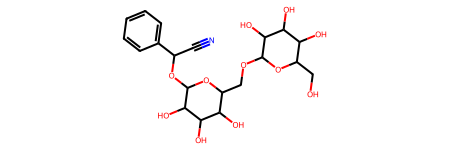

In [9]:
molecule

## Hyperparameters

In [63]:
data_size = len(dataset)
train_size = int(data_size * 0.8)
test_size = int(data_size * 0.1)
val_size = data_size - train_size - test_size  # Remainder for validation

b_size = 32
epochs = 1000
lr = 0.0005
drop_rate = 0.1
n_hide = 128
n_hop = 5
n_feature = 9
n_dcnn = 4

In [64]:
print(f"testing data size: {test_size}")
print(f"validation data size: {val_size}")
print(f"training data size: {train_size}")

testing data size: 112
validation data size: 114
training data size: 901


## Data Loaders

In [65]:
train_loader = DataLoader(dataset[:train_size],
                          batch_size=b_size, shuffle=True)
val_loader = DataLoader(dataset[train_size: train_size+val_size],
                        batch_size=b_size, shuffle=True)
test_loader = DataLoader(dataset[train_size+val_size:],
                         batch_size=b_size, shuffle=True)

In [66]:
for mol in train_loader:
    x, y = mol.x, mol.y
    print(x.shape, y.shape)
    break

torch.Size([367, 9]) torch.Size([32, 1])


## Helpers

In [67]:
def live_plot(train_losses, val_losses, train_maes, val_maes, train_mses, val_mses, train_rmses, val_rmses, train_r2s, val_r2s):
    clear_output(wait=True)

    plt.figure(figsize=(12, 6))

    # Plot training metrics
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss', color='blue')
    plt.plot(train_maes, label='Train MAE', color='green')
    plt.plot(train_mses, label='Train MSE', color='red')
    plt.plot(train_rmses, label='Train RMSE', color='purple')
    plt.plot(train_r2s, label='Train R²', color='brown')
    plt.xlabel('Epoch')
    plt.ylabel('Value')
    plt.title('Training Metrics')
    plt.legend()
    plt.grid(True)

    # Plot validation metrics
    plt.subplot(1, 2, 2)
    plt.plot(val_losses, label='Validation Loss', color='blue')
    plt.plot(val_maes, label='Validation MAE', color='green')
    plt.plot(val_mses, label='Validation MSE', color='red')
    plt.plot(val_rmses, label='Validation RMSE', color='purple')
    plt.plot(val_r2s, label='Validation R²', color='brown')
    plt.xlabel('Epoch')
    plt.ylabel('Value')
    plt.title('Validation Metrics')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


def compute_metrics(x, y):
    # Convert x and y to tensors if they aren't already
    x = torch.tensor(x) if not isinstance(x, torch.Tensor) else x
    y = torch.tensor(y) if not isinstance(y, torch.Tensor) else y

    # Mean Absolute Error
    mae = torch.mean(torch.abs(x - y)).item()

    # Mean Squared Error
    mse = torch.mean((x - y) ** 2)

    # Root Mean Squared Error
    rmse = torch.sqrt(mse).item()

    # R-squared
    mean_y = torch.mean(y)
    ss_total = torch.sum((y - mean_y) ** 2)
    ss_residual = torch.sum((y - x) ** 2)
    r2 = 1 - (ss_residual / ss_total).item()

    return mae, mse.item(), rmse, r2

def trainer(model, loader):
    model.train()
    total_loss = 0
    all_preds = []
    all_targets = []

    for batch in loader:
        x, y, e_idx, b_idx = batch.x.float().to(device), batch.y.float().to(device), batch.edge_index.to(device), batch.batch.to(device)

        # Extremely Important
        optimizer.zero_grad()

        # Forward pass
        pred = model(x=x, e_idx=e_idx, b_idx=b_idx)

        # loss
        loss = loss_fn(pred.squeeze(), y.squeeze())
        total_loss += loss.item()

        # Backward pass
        loss.backward()
        optimizer.step()

        # Collect predictions and targets for metrics calculation
        all_preds.append(pred.cpu().detach())
        all_targets.append(y.cpu().detach())

    avg_loss = total_loss / len(loader)

    # Concatenate all predictions and targets
    all_preds = torch.cat(all_preds)
    all_targets = torch.cat(all_targets)

    # Compute metrics
    mae, mse, rmse, r2 = compute_metrics(all_preds, all_targets)

    return avg_loss, mae, mse, rmse, r2

def validator(model, loader):
    model.eval()
    total_loss = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for batch in loader:
            x, y, e_idx, b_idx = batch.x.float().to(device), batch.y.float().to(device), batch.edge_index.to(device), batch.batch.to(device)

            # Forward pass
            pred = model(x=x, e_idx=e_idx, b_idx=b_idx)

            # Calculate loss
            loss = loss_fn(pred.squeeze(), y.squeeze())
            total_loss += loss.item()

            # Collect predictions and targets for metrics calculation
            all_preds.append(pred.cpu().detach())
            all_targets.append(y.cpu().detach())

    avg_loss = total_loss / len(loader)

    # Concatenate all predictions and targets
    all_preds = torch.cat(all_preds)
    all_targets = torch.cat(all_targets)

    # Compute metrics
    mae, mse, rmse, r2 = compute_metrics(all_preds, all_targets)

    return avg_loss, mae, mse, rmse, r2

## building model

In [68]:
from torch_scatter import scatter_mean
class DCNN(nn.Module):
    def __init__(self, n_feature, n_hop, non_ln="relu"):
        super(DCNN, self).__init__()

        self.n_feature = n_feature
        self.n_hop = n_hop

        # (n_hop + 1, n_feature) including self loop features
        self.W = nn.Parameter(torch.randn(1, self.n_hop + 1, 1, self.n_feature) * 0.01)
        self.non_ln = getattr(F, non_ln)

        # Init the weights
        self.init_params()

    def init_params(self):
        nn.init.xavier_uniform_(self.W)

    def forward(self, P, X):
        # (b_size, n_hop, n_node, n_node) x (b_size, n_node, n_node, n_feature)
        X = X.unsqueeze(1)          # (b_size, 1, n_node, n_feature)
        PX = torch.matmul(P, X)     # (b_size, n_hop, n_node, n_feature)
        W_PX = PX * self.W          # (b_size, n_hop, n_node, n_feature)
        H = self.non_ln(W_PX)       # H = non_fun(W ⊙ PX)
        H = torch.sum(H, dim=1)     # (b_size, n_node, n_feature)
        return H

class GDCNNModel(nn.Module):
    def __init__(self, n_hop, n_hide, n_feature, n_dcnn, non_ln="relu", d_rate=0.0):
        super(GDCNNModel, self).__init__()

        self.n_hop = n_hop
        self.n_feature = n_feature
        self.n_dcnn = n_dcnn
        self.non_ln = non_ln
        self.n_hide = n_hide

        # multi-dcnns layers
        self.dcnns = nn.ModuleList([DCNN(n_feature=n_feature, n_hop=n_hop, non_ln=non_ln) for _ in range(n_dcnn)])

        # Classification Layer
        self.fc = nn.Sequential(
            nn.Linear(n_feature, n_hide),
            nn.ReLU(),
            nn.BatchNorm1d(n_hide),
            nn.Dropout(p=d_rate),
            nn.Linear(n_hide, 1),
        )

        # Feature Normalization Layer
        self.feature_norm = nn.BatchNorm1d(n_feature)

    def forward(self, x, e_idx, b_idx):
        """
        A : adjacency matrix  (b_size, n_node, n_node)
        P : diffusion kernel  (b_size, n_hop, n_node, n_node)
        x : node features     (b_size, n_node, n_feature)
        """
        A = to_dense_adj(edge_index=e_idx, batch=b_idx)
        P = self.create_diffusion_kernel(A, self.n_hop)  # (b_size, n_hop, n_node, n_node)

        x = self.feature_norm(x) # Normalize

        # Convert batch indices to dense format
        x, mask = to_dense_batch(x, batch=b_idx)  # (b_size, n_node, n_feature)

        # dcnn + res connect
        for dcnn in self.dcnns:
            x = x + dcnn(P, x)  # (b_size, n_node, n_feature)

        # Flatten the node features (b_size * n_node, n_feature)
        b_size, n_node, n_feature = x.shape
        x = x.view(-1, n_feature)  # (b_size * n_node, n_feature)

        # Recalculate batch indices after dense conversion
        b_idx = torch.arange(b_size).repeat_interleave(n_node).to(x.device)  # (b_size * n_node)

        x = scatter_mean(x, b_idx, dim=0)   # (b_size, n_feature)

        # projection layer
        x = self.fc(x)        # (b_size, 1)
        return x

    def create_diffusion_kernel(self, A, k):
        """
        Pi = [P^1, P^2, ..., P^k].
        P = D^-1 * A, where D is the degree matrix and A is the adjacency matrix.

        Output:
        - Pi.shape = [b_size, n_hop, n_node, n_node]
        - D.shape  = [b_size, n_node, n_node]
        """
        b_size, n_node, _ = A.shape

        # D = Degre(A) + I: (b_size, n_hop, n_node, n_node)
        D = torch.diag_embed(A.sum(dim=-1)) + torch.eye(n_node, device=A.device).unsqueeze(0).repeat(b_size, 1, 1)

        # D_inv is the inverse of the degree matrix D
        D_inv = torch.inverse(D)  # (b_size, n_node, n_node)

        # Transition matrix P = D^-1 * A
        P = torch.matmul(D_inv, A)  # (b_size, n_node, n_node)

        # P^0 = I
        Pi = [torch.eye(n_node, device=A.device).unsqueeze(0).repeat(b_size, 1, 1)]   # (b_size, n_node, n_node)

        # Compute P^1 to P^k
        for i in range(1, k + 1):
            Pi.append(torch.matmul(Pi[-1], P))  # P^i

        Pi = torch.stack(Pi, dim=1)   # (b_size, n_hop, n_node, n_node)
        return Pi


# # Example Usage
model = GDCNNModel(n_hop=4, n_feature=9, n_hide=128, n_dcnn=4, non_ln="relu", d_rate=0.0)
print(model)
for batch in train_loader:
    x, y, e_idx, b_idx = batch.x.float(), batch.y.float(), batch.edge_index, batch.batch
    logits = model(x=x, e_idx=e_idx, b_idx=b_idx)
    print(logits.shape)
    break

GDCNNModel(
  (dcnns): ModuleList(
    (0-3): 4 x DCNN()
  )
  (fc): Sequential(
    (0): Linear(in_features=9, out_features=128, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
  (feature_norm): BatchNorm1d(9, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)
Pi.shape : torch.Size([32, 5, 23, 23])
torch.Size([32, 1])


In [69]:
# # Define model parameters
# model = GDCNNModel(n_hop=8, n_feature=9, n_hide=128, n_dcnn=4, non_ln="relu", d_rate=0.0)

# # print("Model Summary:")
# # print(model)

# for i, batch in enumerate(val_loader):
#     x, y, e_idx, b_idx = batch.x.float(), batch.y.float(), batch.edge_index, batch.batch

#     # if i == 0:
#     print("\nData Info:")
#     print(f"{'Variable':<10} {'Type':<20} {'Shape'}")
#     print(f"{'-'*40}")
#     print(f"{'x':<10} {str(type(x)):<20} {x.shape}")
#     print(f"{'y':<10} {str(type(y)):<20} {y.shape}")
#     print(f"{'e_idx':<10} {str(type(e_idx)):<20} {e_idx.shape}")
#     print(f"{'b_idx':<10} {str(type(b_idx)):<20} {b_idx.shape}\n")

#     logits = model(x=x, e_idx=e_idx, b_idx=b_idx)

#     print(f"logits: {logits.shape}")

## Init objects

In [70]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = GDCNNModel(n_hop=1, n_feature=9, n_hide=128, n_dcnn=4, non_ln="relu", d_rate=0.0).to(device)
loss_fn = torch.nn.MSELoss(reduction='mean')
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

## Train the Model

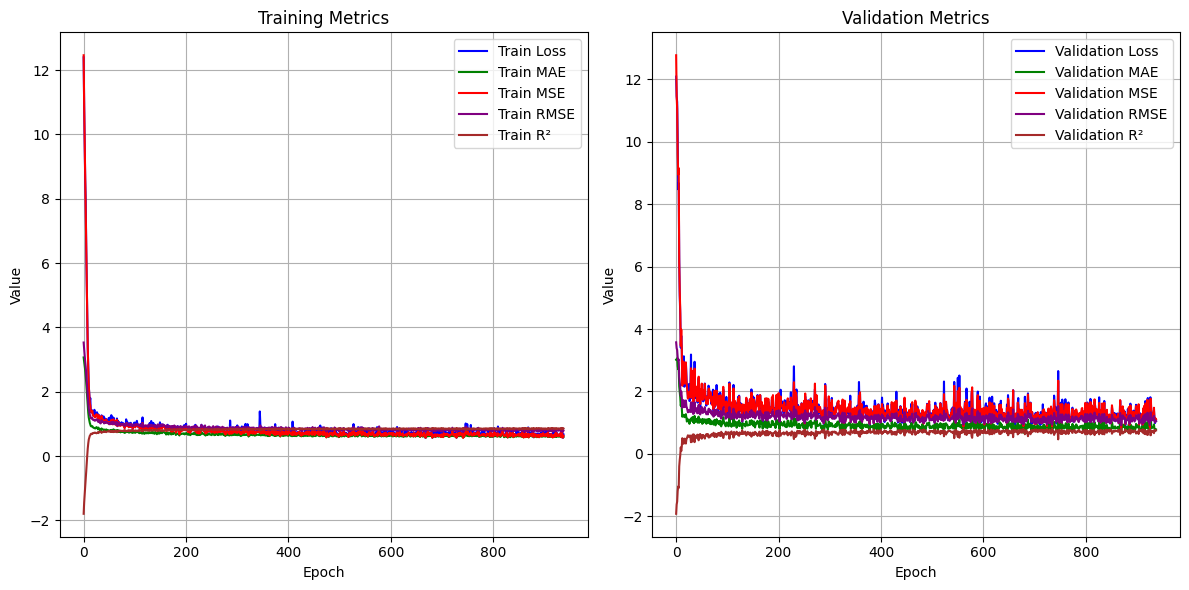

Pi.shape : torch.Size([32, 2, 33, 33])
Pi.shape : torch.Size([32, 2, 29, 29])
Pi.shape : torch.Size([32, 2, 35, 35])
Pi.shape : torch.Size([32, 2, 30, 30])
Pi.shape : torch.Size([32, 2, 23, 23])
Pi.shape : torch.Size([32, 2, 26, 26])
Pi.shape : torch.Size([32, 2, 22, 22])
Pi.shape : torch.Size([32, 2, 27, 27])
Pi.shape : torch.Size([32, 2, 29, 29])
Pi.shape : torch.Size([32, 2, 34, 34])
Pi.shape : torch.Size([32, 2, 24, 24])
Pi.shape : torch.Size([32, 2, 32, 32])
Pi.shape : torch.Size([32, 2, 55, 55])
Pi.shape : torch.Size([32, 2, 26, 26])
Pi.shape : torch.Size([32, 2, 27, 27])
Pi.shape : torch.Size([32, 2, 23, 23])
Pi.shape : torch.Size([32, 2, 34, 34])
Pi.shape : torch.Size([32, 2, 26, 26])
Pi.shape : torch.Size([32, 2, 42, 42])
Pi.shape : torch.Size([32, 2, 31, 31])
Pi.shape : torch.Size([32, 2, 34, 34])
Pi.shape : torch.Size([32, 2, 54, 54])
Pi.shape : torch.Size([32, 2, 26, 26])
Pi.shape : torch.Size([32, 2, 31, 31])
Pi.shape : torch.Size([32, 2, 30, 30])
Pi.shape : torch.Size([32

In [ ]:
# Initialize lists to store metrics
train_losses = []
val_losses = []
train_maes = []
val_maes = []
train_mses = []
val_mses = []
train_rmses = []
val_rmses = []
train_r2s = []
val_r2s = []

print("Starting training...")

# Run training for a specified number of epochs
for epoch in range(epochs):
    # Training phase
    tr_loss, tr_mae, tr_mse, tr_rmse, tr_r2 = trainer(model, train_loader)
    train_losses.append(tr_loss)
    train_maes.append(tr_mae)
    train_mses.append(tr_mse)
    train_rmses.append(tr_rmse)
    train_r2s.append(tr_r2)

    # Validation phase
    val_loss, val_mae, val_mse, val_rmse, val_r2 = validator(model, val_loader)
    val_losses.append(val_loss)
    val_maes.append(val_mae)
    val_mses.append(val_mse)
    val_rmses.append(val_rmse)
    val_r2s.append(val_r2)

    # Plot live metrics
    live_plot(train_losses, val_losses, train_maes, val_maes, train_mses, val_mses, train_rmses, val_rmses, train_r2s, val_r2s)